# Cleaning the Data EDA
## part 1


### Imports

In [123]:
import numpy as np, \
       pandas as pd, \
       matplotlib.pyplot as plt, \
       seaborn as sns
from sklearn.model_selection import (
    train_test_split as tts,
    cross_val_score as cvs,
    cross_validate as cv,
    StratifiedKFold,
    GridSearchCV,
)
from sklearn.preprocessing import (
    StandardScaler as SS,
    MinMaxScaler as MMS,
    OneHotEncoder as OHE,
    LabelEncoder as LE,
    OrdinalEncoder as OE,
)
from sklearn.metrics import (
    accuracy_score as acc,
    classification_report as cr,
    confusion_matrix as cm,
    f1_score,
    ConfusionMatrixDisplay as CMD,
)
from sklearn.impute import SimpleImputer as SI
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer as CT
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression as LogReg
from sklearn.ensemble import RandomForestClassifier as RFC
from sklearn.tree import DecisionTreeClassifier as DTC
from sklearn.svm import SVC as SVC

In [70]:
data = pd.read_csv('../data/student_mental_health.csv', encoding='utf-8')

data.head()

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium


In [71]:
data.describe()
data.shape
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Student_ID                      2000 non-null   str    
 1   Age                             2000 non-null   int64  
 2   Gender                          2000 non-null   str    
 3   Year_of_Study                   2000 non-null   int64  
 4   Sleep_Hours                     1938 non-null   float64
 5   Study_Hours_Per_Week            2000 non-null   float64
 6   GPA                             1962 non-null   float64
 7   Social_Media_Hours              1942 non-null   float64
 8   Screen_Time_Hours               2000 non-null   float64
 9   Physical_Activity               2000 non-null   str    
 10  Financial_Stress                1909 non-null   float64
 11  Family_Support                  1946 non-null   float64
 12  Attendance_Rate                 1953 non-null

In [72]:
display(data.isnull().sum(),data.duplicated().sum())


Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64

np.int64(0)

In [73]:
cat_cols = []
num_cols = []

for col in data.columns[1:]:
    if data[col].dtype == 'str':
        cat_cols.append(col)
    else:
        num_cols.append(col)

cat = data[cat_cols]
num = data[num_cols]

display(cat.head())
display(num.head())


,Gender,Physical_Activity,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,Male,Moderate,No,Poor,No,High
1,Male,Low,Yes,Average,No,Medium
2,Male,Low,No,Average,No,Medium
3,Male,High,No,Average,Yes,High
4,Female,Moderate,Yes,NaN,No,Medium


,Age,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Financial_Stress,Family_Support,Attendance_Rate
0,22,3,6.6,17.6,2.91,6.9,7.5,8.5,4.0,78.0
1,21,4,5.6,22.4,2.92,7.6,11.5,4.5,5.3,85.4
2,22,5,7.1,28.1,2.68,6.5,8.9,4.8,6.1,79.5
3,24,1,4.5,14.8,2.23,5.5,7.6,3.7,8.0,73.9
4,20,1,6.7,17.2,2.69,4.3,7.0,8.0,7.4,99.8


In [74]:
for i, col in enumerate(data.columns[1:], start=1):
    if (data[col].dtype == 'str'):
        display(data[col].value_counts())
    else:
        display(data[col].describe())

count    2000.000000
mean       21.131500
std         2.139275
min        17.000000
25%        20.000000
50%        21.000000
75%        23.000000
max        29.000000
Name: Age, dtype: float64

Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64

count    2000.000000
mean        2.630000
std         1.316802
min         1.000000
25%         1.000000
50%         2.000000
75%         4.000000
max         5.000000
Name: Year_of_Study, dtype: float64

count    1938.000000
mean        6.758875
std         1.127072
min         3.300000
25%         6.000000
50%         6.700000
75%         7.600000
max        10.000000
Name: Sleep_Hours, dtype: float64

count    2000.000000
mean       19.997900
std         5.719274
min         2.400000
25%        16.000000
50%        19.800000
75%        24.000000
max        38.300000
Name: Study_Hours_Per_Week, dtype: float64

count    1962.000000
mean        2.562503
std         0.343993
min         1.500000
25%         2.320000
50%         2.560000
75%         2.790000
max         3.660000
Name: GPA, dtype: float64

... (6 outputs left out)

Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64

Diet_Quality
Average    860
Poor       587
Good       484
Name: count, dtype: int64

Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64

Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64

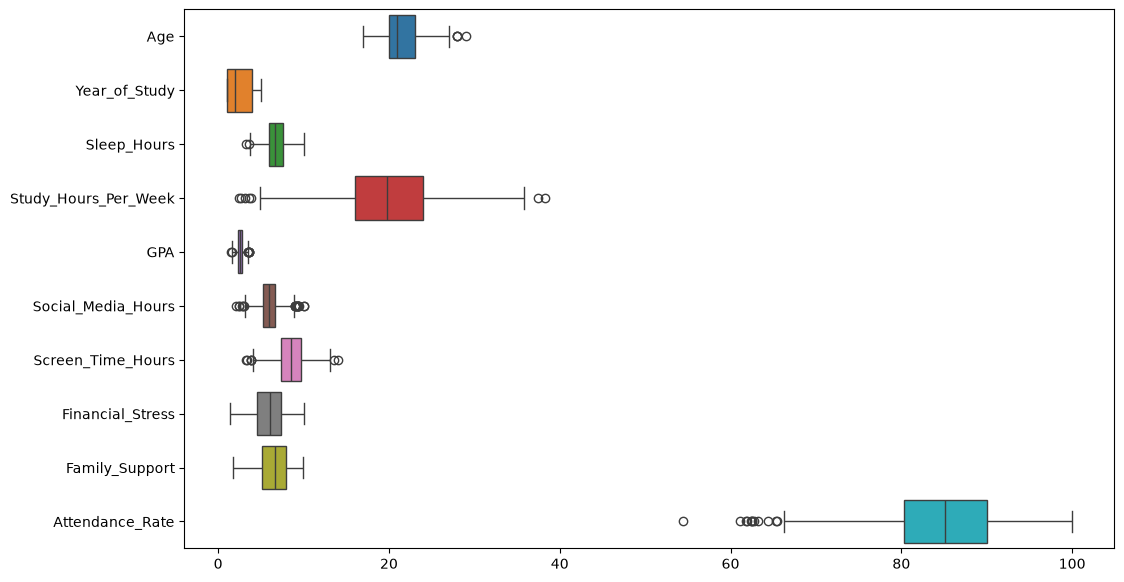

In [75]:
plt.figure(figsize=(12, 7))
sns.boxplot(data=num, orient='h')
plt.show()

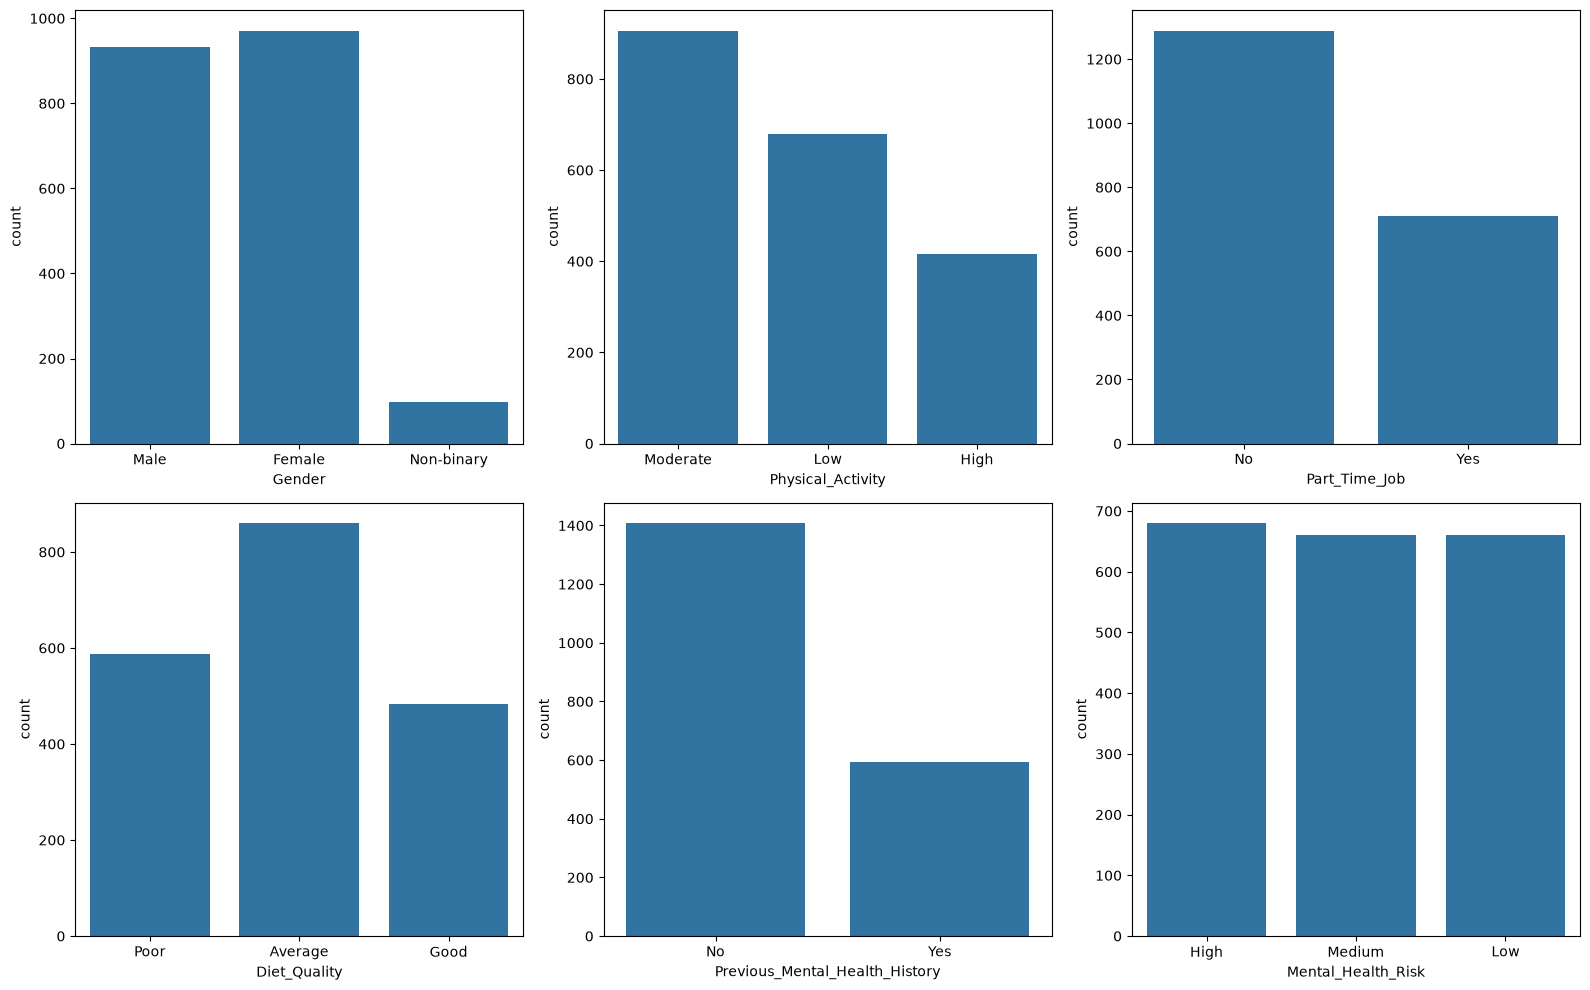

In [76]:
plt.figure(figsize=(16, 10))
for i, col in enumerate(cat.columns, 1):
    plt.subplot(2, 3, i)
    sns.countplot(data=cat, x=col)
plt.tight_layout()
plt.show()

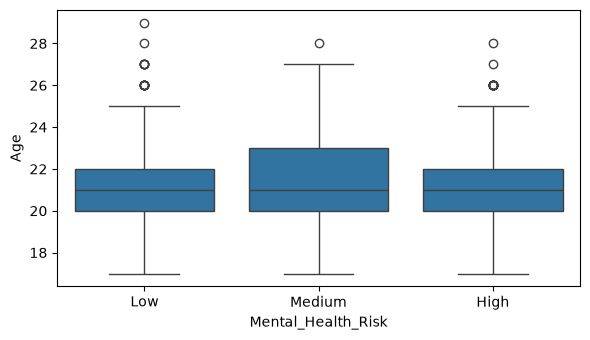

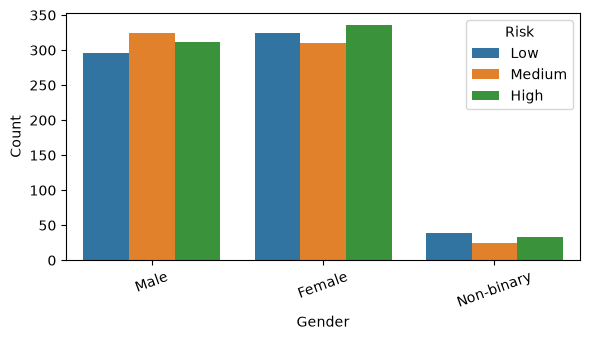

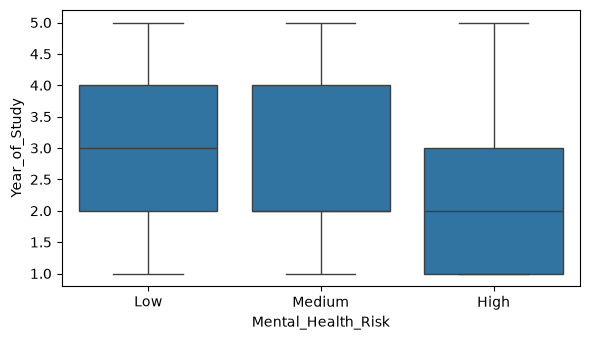

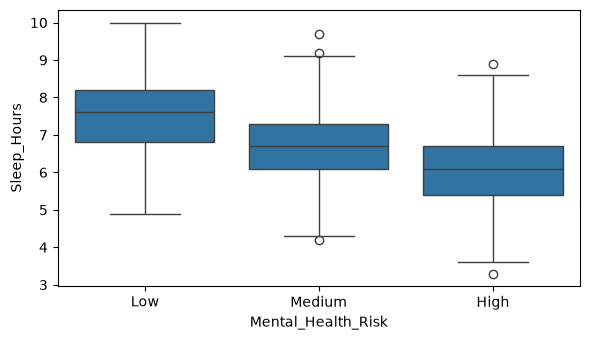

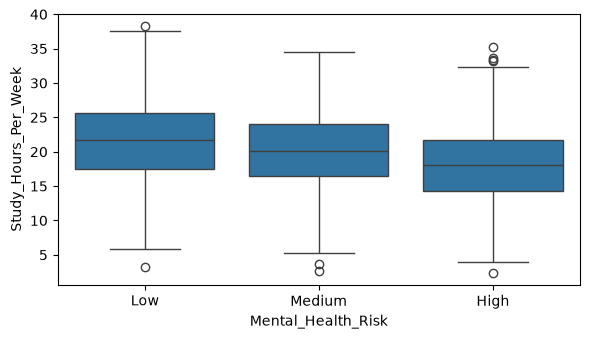

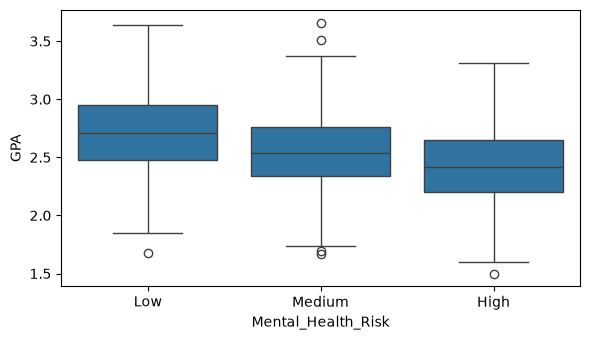

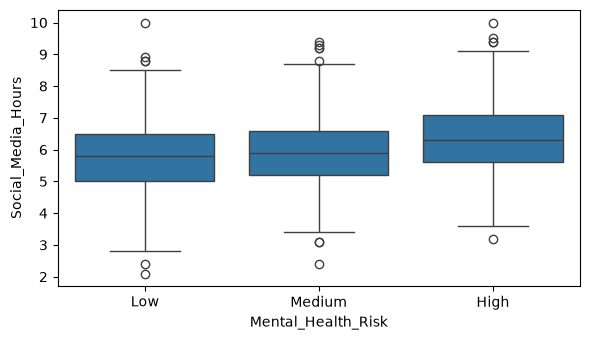

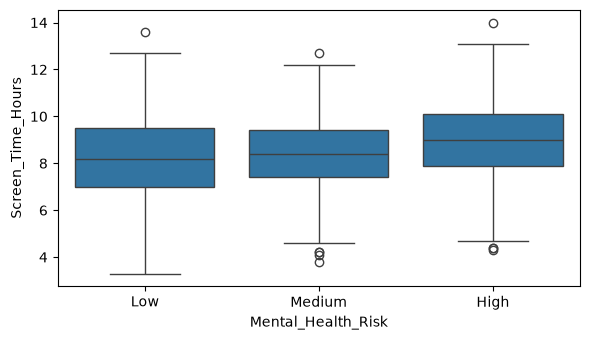

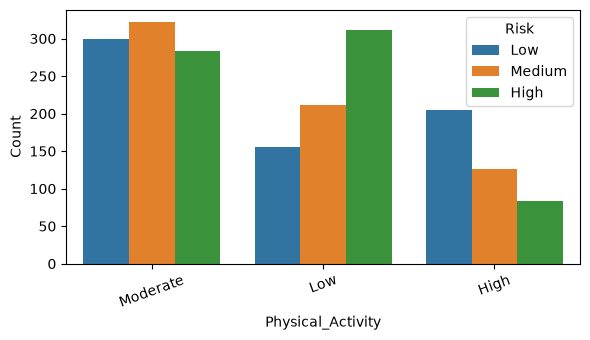

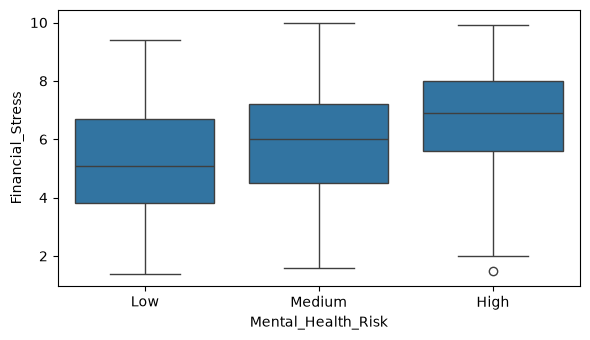

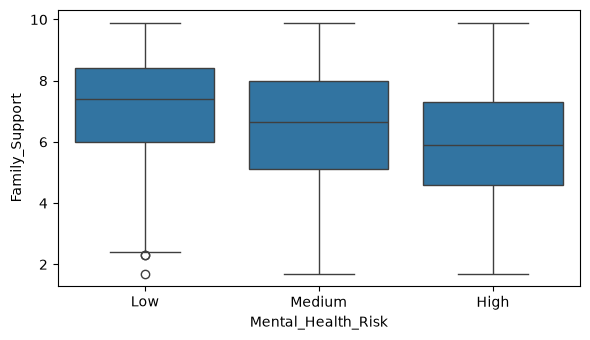

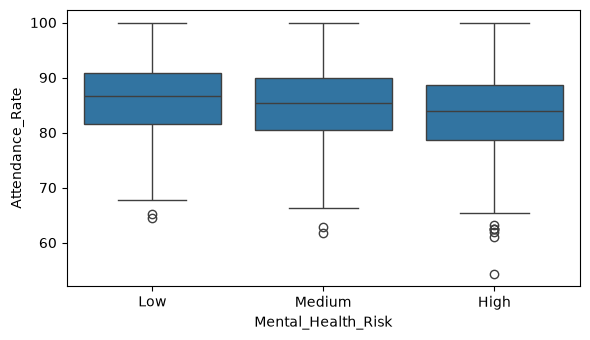

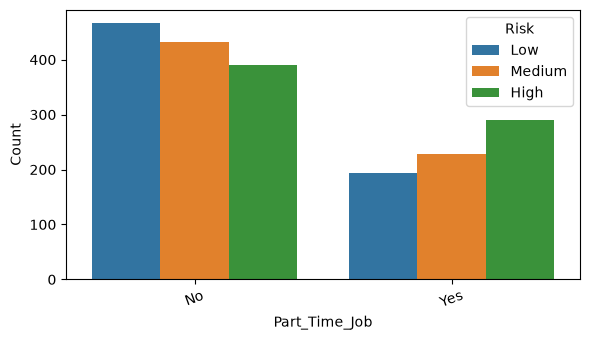

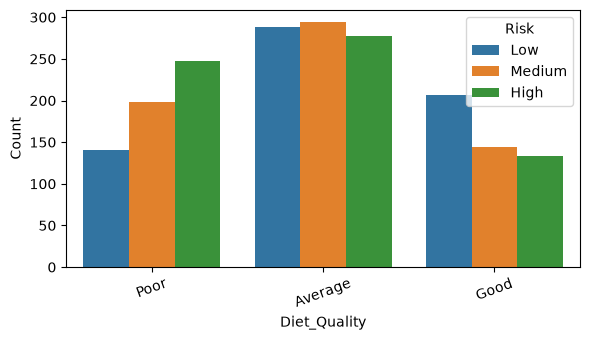

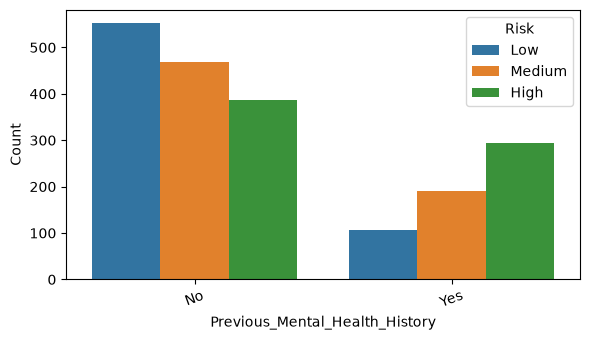

In [77]:
risk_order = ['Low', 'Medium', 'High']

def check_feature(col):
    plt.figure(figsize=(6, 3.5))
    
    if data[col].dtype in ['int64', 'float64']:
        sns.boxplot(data=data, x='Mental_Health_Risk', y=col, order=risk_order)
        plt.ylabel(col)
        
    else:
        sns.countplot(data=data, x=col, hue='Mental_Health_Risk', hue_order=risk_order)
        plt.xlabel(col)
        plt.ylabel('Count')
        plt.xticks(rotation=20)
        plt.legend(title='Risk', loc='upper right')
        
    plt.tight_layout()
    plt.show()

features = [c for c in data.columns if c not in ['Student_ID', 'Mental_Health_Risk']]

for col in features:
    check_feature(col)

<Axes: >

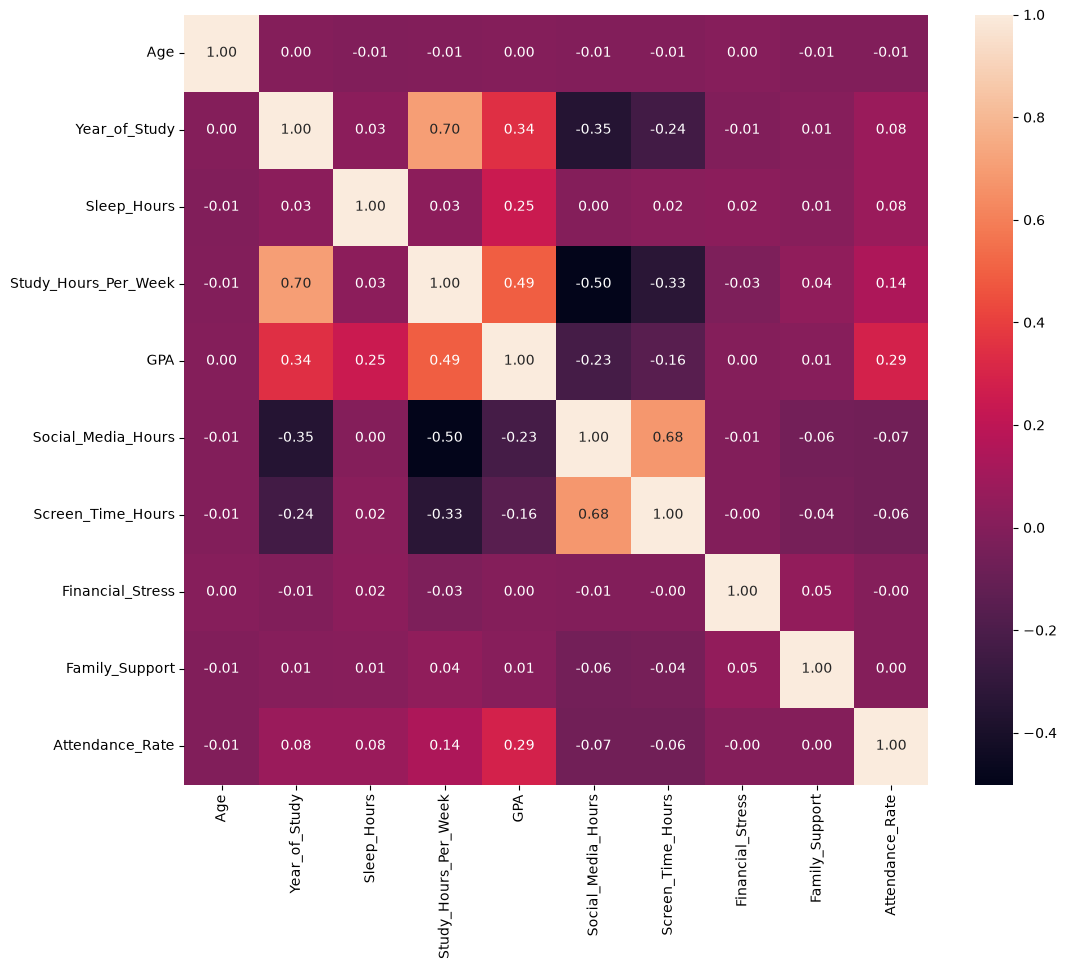

In [78]:
corr = num.corr()

plt.figure(figsize=(12,10))
sns.heatmap(corr,annot=True,fmt='0.2f')

In [79]:
X = data.drop(columns=['Student_ID', 'Mental_Health_Risk'])
y = data['Mental_Health_Risk']

In [80]:
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['str']).columns.tolist()

In [81]:
X_train, X_test, y_train, y_test = tts(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

In [82]:
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")

X_train shape: (1600, 15)
X_test shape:  (400, 15)


itertiveimputer

In [ ]:
num_pipeline = Pipeline(steps=[
    ('imputer', SI(strategy='median')),
    ('scaler', SS())
])

In [ ]:
cat_pipeline = Pipeline(steps=[
    ('imputer', SI(strategy='most_frequent')),
    ('encoder', OHE(handle_unknown='ignore', sparse_output=False))
])

In [85]:
preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

In [86]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
print("Processed training data shape:", X_train_processed.shape)
print("Processed testing data shape: ", X_test_processed.shape)

Processed training data shape: (1600, 23)
Processed testing data shape:  (400, 23)


In [87]:
risk_mapping = {'Low': 0, 'Medium': 1, 'High': 2}
y_train_encoded = y_train.map(risk_mapping)
y_test_encoded = y_test.map(risk_mapping)
y_train_encoded.value_counts()

Mental_Health_Risk
2    544
1    528
0    528
Name: count, dtype: int64

In [124]:
models = {
    'Logistic Regression': LogReg(max_iter=1000, random_state=42),
    'Random Forest': RFC(random_state=42),
    'SVM': SVC(random_state=42)
}

scoring = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
results = []

for name, model in models.items():
    scores = cv(model, X_train_processed, y_train_encoded, cv=5, scoring=scoring)
    results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision_macro'].mean(),
        'Recall': scores['test_recall_macro'].mean(),
        'F1_Macro': scores['test_f1_macro'].mean()
    })

comparison_df = pd.DataFrame(results).sort_values(by='F1_Macro', ascending=False)
display(comparison_df)

,Model,Accuracy,Precision,Recall,F1_Macro
0,Logistic Regression,0.754375,0.753655,0.753758,0.753059
2,SVM,0.705625,0.711115,0.705162,0.707063
1,Random Forest,0.679375,0.672614,0.678377,0.673575


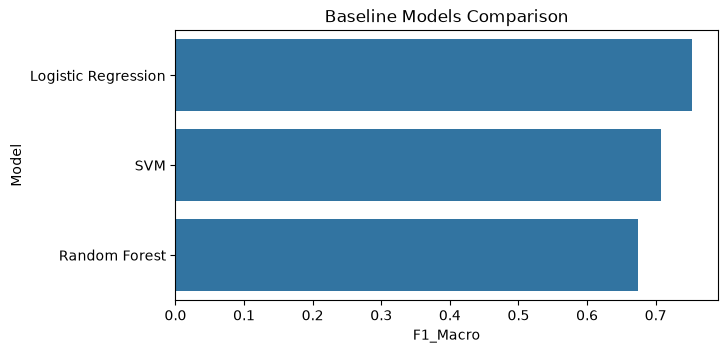

In [125]:
plt.figure(figsize=(7, 3.5))
sns.barplot(data=comparison_df, x='F1_Macro', y='Model')
plt.title('Baseline Models Comparison')
plt.show()